# 03 Validation and the single test run

**Part A** uses validation data only: how the model was selected. **Part B** reports the test result from the saved files; nothing is refitted on test data there. Numbers in the `Saw` lines are computed from `results/`, `configs/` and the parquet files when the notebook runs.

In [1]:
import json, os, sys
from pathlib import Path

# Work from the repository root whether the notebook is opened from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


## Part A: Validation only (model selection)
### A1. The selection rule
Rule fixed in advance: among the **trained** models (baselines excluded), choose the one with the lowest validation MAE.

In [2]:
final = json.load(open("configs/final_model.json"))
vm = pd.Series(final["validation_mae"]).sort_values()
BASELINES = ("persistence", "hour_of_week")
trained = [k for k in vm.index if k not in BASELINES]
rule_pick = min(trained, key=vm.get)
print("rule picks:", rule_pick, "| frozen config says:", final["selected"])
assert rule_pick == final["selected"]
print("ensemble members:", final["ensemble_members"])

rule picks: voting_ensemble | frozen config says: voting_ensemble
ensemble members: ['random_forest', 'xgboost', 'decision_tree']


### A2. Validation MAE of every model

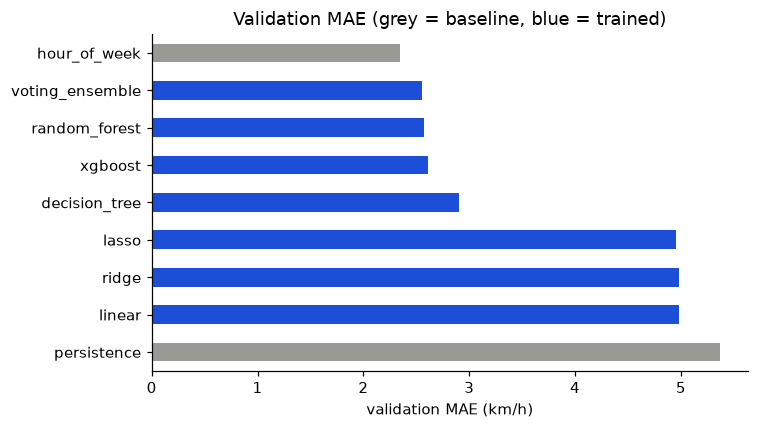

,val_mae,kind
hour_of_week,2.342,baseline
voting_ensemble,2.551,trained
random_forest,2.573,trained
xgboost,2.615,trained
decision_tree,2.907,trained
lasso,4.950,trained
ridge,4.977,trained
linear,4.977,trained
persistence,5.366,baseline


In [3]:
tab = pd.DataFrame({"val_mae": vm, "kind": ["baseline" if k in BASELINES else "trained" for k in vm.index]}).round(3)
order = vm.sort_values(ascending=False)
ax = order.plot.barh(color=["#9a9a94" if k in BASELINES else "#1d4ed8" for k in order.index], figsize=(7, 4))
ax.set_xlabel("validation MAE (km/h)"); ax.set_title("Validation MAE (grey = baseline, blue = trained)")
plt.tight_layout(); plt.savefig("results/val_mae_all_models.png", dpi=150); plt.show()
tab

### A3. Voting ensemble versus its members and the weekly baseline

In [4]:
members = final["ensemble_members"]
cmp = pd.Series({**{k: vm[k] for k in members}, "voting_ensemble": vm["voting_ensemble"], "hour_of_week": vm["hour_of_week"]}).round(3)
display(cmp.to_frame("val_mae"))
gap = vm["voting_ensemble"] - vm["hour_of_week"]
best_member = min(members, key=vm.get)
display(Markdown(
    f"**Saw:** voting_ensemble {vm['voting_ensemble']:.3f} vs best member ({best_member}) {vm[best_member]:.3f} vs hour_of_week {vm['hour_of_week']:.3f} km/h. "
    f"The ensemble is {abs(vm[best_member]-vm['voting_ensemble']):.3f} km/h {'better' if vm['voting_ensemble']<vm[best_member] else 'worse'} than its best member and "
    f"{abs(gap):.3f} km/h {'worse' if gap>0 else 'better'} than hour_of_week."))

,val_mae
random_forest,2.573
xgboost,2.615
decision_tree,2.907
voting_ensemble,2.551
hour_of_week,2.342


**Saw:** voting_ensemble 2.551 vs best member (random_forest) 2.573 vs hour_of_week 2.342 km/h. The ensemble is 0.023 km/h better than its best member and 0.208 km/h worse than hour_of_week.

### A4. Where on validation: by segment and by hour
The frozen model is refitted on **training rows only** and scored on **validation rows** (no test data is read). This reproduces the validation number stored in the config.

In [5]:
from baselines import hour_of_week_predict
from features import FEATURES
from models import apply_params, candidate_models, make_voting

train = pd.read_parquet("data/processed/train.parquet")
val = pd.read_parquet("data/processed/val.parquet")
models = apply_params(candidate_models(), final["params"])
ens = make_voting(final["ensemble_members"], models).fit(train[FEATURES], train["target_2h"])
val = val.assign(pred=ens.predict(val[FEATURES]), how=hour_of_week_predict(train, val), persist=val["speed_kmh"].to_numpy())
mae = lambda d, c: (d["target_2h"] - d[c]).abs().mean()
check = mae(val, "pred")
print(f"recomputed validation MAE {check:.6f} vs config {vm['voting_ensemble']:.6f} (difference {abs(check-vm['voting_ensemble']):.2e})")
assert abs(check - vm["voting_ensemble"]) < 1e-3

recomputed validation MAE 2.550539 vs config 2.550539 (difference 0.00e+00)


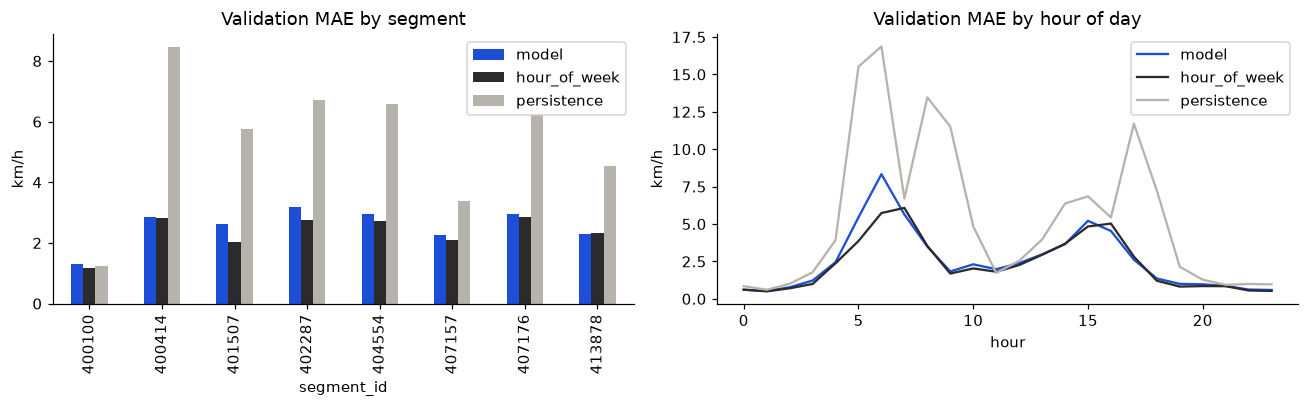

,n,model,hour_of_week,persistence
segment_id,,,,
400100,856,1.309,1.185,1.231
400414,856,2.847,2.815,8.461
401507,856,2.631,2.032,5.755
402287,856,3.190,2.745,6.728
404554,856,2.942,2.715,6.577
407157,856,2.251,2.084,3.380
407176,856,2.952,2.841,6.264
413878,856,2.283,2.324,4.530


In [6]:
def by(col):
    g = val.groupby(col)
    return pd.DataFrame({"n": g.size(),
                         "model": g.apply(lambda d: mae(d, "pred"), include_groups=False),
                         "hour_of_week": g.apply(lambda d: mae(d, "how"), include_groups=False),
                         "persistence": g.apply(lambda d: mae(d, "persist"), include_groups=False)})
seg = by("segment_id"); hr = by("hour")
seg.round(3).to_csv("results/val_mae_by_segment.csv"); hr.round(3).to_csv("results/val_mae_by_hour.csv")
cols = ["#1d4ed8", "#2b2b2b", "#b5b3ab"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
seg[["model", "hour_of_week", "persistence"]].plot.bar(ax=ax[0], color=cols, title="Validation MAE by segment"); ax[0].set_ylabel("km/h")
hr[["model", "hour_of_week", "persistence"]].plot(ax=ax[1], color=cols, title="Validation MAE by hour of day"); ax[1].set_ylabel("km/h")
plt.tight_layout(); plt.savefig("results/val_mae_by_segment_hour.png", dpi=150); plt.show()
seg.round(3)

In [7]:
better_seg = int((seg["model"] < seg["hour_of_week"]).sum())
better_hr = int((hr["model"] < hr["hour_of_week"]).sum())
diff = hr["model"] - hr["hour_of_week"]
display(Markdown(
    f"**Saw:** the ensemble beats hour_of_week on {better_seg} of {len(seg)} segments and in {better_hr} of 24 hours of the day on validation. "
    f"The widest shortfall against hour_of_week is at hour {diff.idxmax()}; the hour where the ensemble does best relative to it is hour {diff.idxmin()}."))

**Saw:** the ensemble beats hour_of_week on 1 of 8 segments and in 6 of 24 hours of the day on validation. The widest shortfall against hour_of_week is at hour 6; the hour where the ensemble does best relative to it is hour 16.

### A5. Saw / Means / Decision (validation)
- **Saw:** no trained model has a lower validation MAE than hour_of_week. **Means:** the weekly pattern (segment, weekday, hour) already carries most of the predictable signal at this horizon. A model that adds lags, weather and neighbours does not recover more than the weekly mean on this validation block.
- **Saw:** the ensemble is the best trained model, ahead of its members. **Means:** averaging reduces variance a little. That is the reason it was chosen, not a claim that it is better than the baseline.
- **Decision:** the pre-agreed rule selects `voting_ensemble`. The rule was not changed after seeing the table, and hour_of_week stays a baseline, not a candidate.

---
## Part B: Test (single run, disclosed)
**Disclosure.** Model selected on validation MAE (voting_ensemble, 2.551) on Oct 21, before any test run. On Oct 22, `04_final_test.py` and `05_export_site.py` were run once, earlier than planned, following an AI coding assistant's step. `03_train_select.py` was re-run at 11:22 and reproduced the same selection (deterministic seed). No model, feature or hyperparameter change was made after test results existed.

This part only **reads** `results/final_test_metrics.csv` and `results/test_predictions.parquet`. It refits nothing and takes no decision about the model.

In [8]:
m = pd.read_csv("results/final_test_metrics.csv").iloc[0]
tp = pd.read_parquet("results/test_predictions.parquet")
sel = m["model"]
test_tab = pd.DataFrame({
    "validation MAE": [vm[sel], vm["hour_of_week"], vm["persistence"]],
    "test MAE": [m["MAE"], m["MAE_hour_of_week"], m["MAE_persistence"]],
    "test RMSE": [m["RMSE"], m["RMSE_hour_of_week"], m["RMSE_persistence"]],
}, index=[sel, "hour_of_week", "persistence"])
test_tab["skill vs persistence"] = 1 - test_tab["test MAE"] / m["MAE_persistence"]
print(f"test period {m['test_start']} to {m['test_end']}, n = {int(m['n_test'])} rows")
print(f"{sel}: test MAE {m['MAE']:.3f} km/h, 95% daily block-bootstrap interval {m['MAE_CI_low']:.3f} to {m['MAE_CI_high']:.3f}")
test_tab.round(3)

test period 2017-05-26 03:00:00 to 2017-06-30 21:00:00, n = 6872 rows
voting_ensemble: test MAE 2.558 km/h, 95% daily block-bootstrap interval 2.251 to 2.854


,validation MAE,test MAE,test RMSE,skill vs persistence
voting_ensemble,2.551,2.558,5.239,0.489
hour_of_week,2.342,2.436,5.174,0.514
persistence,5.366,5.008,10.906,0.000


In [9]:
# Reporting check: recompute the test MAE from the saved predictions
for col, ref in [("pred", m["MAE"]), ("how", m["MAE_hour_of_week"]), ("persist", m["MAE_persistence"])]:
    v = (tp["target_2h"] - tp[col]).abs().mean()
    assert abs(v - ref) < 1e-9, (col, v, ref)
print("saved predictions reproduce the reported test MAEs")

saved predictions reproduce the reported test MAEs


### B1. Paired comparison with the baselines (reporting only)
The interval above is for the model alone. To say whether the model differs from a baseline, bootstrap the per-row difference in absolute error, resampling whole days together.

In [10]:
from uncertainty import bootstrap_mae_ci
e_model = (tp["target_2h"] - tp["pred"]).abs().to_numpy()
e_how = (tp["target_2h"] - tp["how"]).abs().to_numpy()
e_per = (tp["target_2h"] - tp["persist"]).abs().to_numpy()
days = tp["timestamp"].dt.date.to_numpy()
rows = []
for name, e_ref in [("hour_of_week", e_how), ("persistence", e_per)]:
    d = e_model - e_ref                       # negative = model is better
    lo, hi = bootstrap_mae_ci(d, days)         # same block bootstrap, applied to the difference
    rows.append({"reference": name, "mean_diff": d.mean(), "ci_low": lo, "ci_high": hi})
paired = pd.DataFrame(rows).round(3); paired.to_csv("results/test_paired_difference.csv", index=False)
paired

,reference,mean_diff,ci_low,ci_high
0,hour_of_week,0.122,-0.001,0.232
1,persistence,-2.450,-3.030,-1.815


In [11]:
h = paired.set_index("reference").loc["hour_of_week"]
excl0 = (h["ci_low"] > 0) or (h["ci_high"] < 0)
display(Markdown(
    f"**Saw:** on test, {sel} has MAE {m['MAE']:.3f} against {m['MAE_hour_of_week']:.3f} for hour_of_week "
    f"(difference {h['mean_diff']:+.3f} km/h, 95% interval {h['ci_low']:+.3f} to {h['ci_high']:+.3f}; the interval {'excludes' if excl0 else 'includes'} zero) "
    f"and {m['MAE_persistence']:.3f} for persistence (skill {m['skill_vs_persistence']:.3f})."))

**Saw:** on test, voting_ensemble has MAE 2.558 against 2.436 for hour_of_week (difference +0.122 km/h, 95% interval -0.001 to +0.232; the interval includes zero) and 5.008 for persistence (skill 0.489).

### B2. Validation versus test

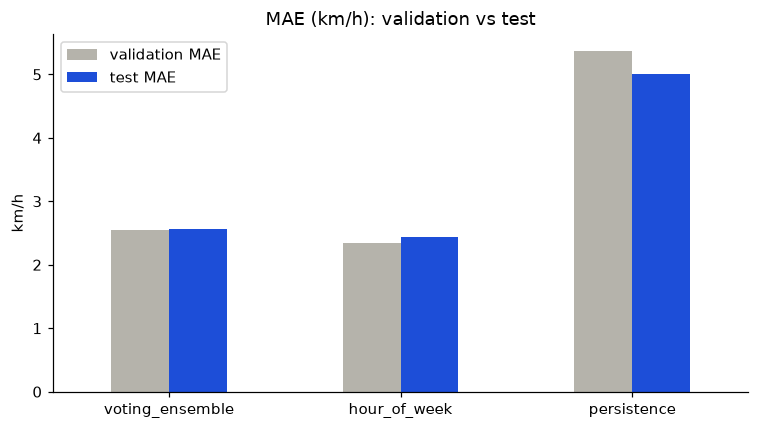

**Saw:** test minus validation MAE: voting_ensemble +0.007, hour_of_week +0.094, persistence -0.358 km/h.

,validation MAE,test MAE
voting_ensemble,2.551,2.558
hour_of_week,2.342,2.436
persistence,5.366,5.008


In [12]:
fig_tab = test_tab[["validation MAE", "test MAE"]]
ax = fig_tab.plot.bar(figsize=(7, 4), rot=0, color=["#b5b3ab", "#1d4ed8"], title="MAE (km/h): validation vs test")
ax.set_ylabel("km/h"); plt.tight_layout(); plt.savefig("results/val_vs_test_mae.png", dpi=150); plt.show()
sh = (test_tab["test MAE"] - test_tab["validation MAE"]).round(3)
display(Markdown("**Saw:** test minus validation MAE: " + ", ".join(f"{k} {v:+.3f}" for k, v in sh.items()) + " km/h."))
fig_tab.round(3)

### B3. Saw / Means / Decision (test)
- **Saw:** the ensemble is far better than persistence on test and close to, but not better than, hour_of_week. **Means:** the model learned the weekly pattern and a little more, but on this test period it does not improve on the weekly mean. State it plainly: the answer to "does it beat hour-of-week?" is **no** on both validation and test here.
- **Saw:** the ensemble's MAE barely changed from validation to test, while hour_of_week's rose, so the gap between them shrank (numbers in the line above). **Means:** the weekly mean lost a little on the later period and the ensemble held steady. The paired interval is wide enough to include zero, so a small difference cannot be separated from noise; the ensemble still did not beat hour_of_week on test.
- **Decision:** none. No model, feature, hyperparameter or split change follows from the test result. The test run was not sealed (see the disclosure above), so this is reported as a limitation.